# Notebook 06 — Evaluación en Producción, Deriva, $T^2$/SPE y Kalman

## Sensores Virtuales y Analizadores en Línea

Un modelo excelente en Validación puede degradarse en Producción cuando cambia el proceso o se ensucia un instrumento.
En nuestro conjunto de **Prueba (Q4: Oct–Dic)** coexisten:
- Una **deriva progresiva del termopozo** de hasta `+4.2 °C` en `kerosene_draw_temp_C`
- Una **excursión de crudo extra-pesado** en noviembre (`API ~26.4`)

Aquí evaluamos cuatro capas defensivas de nivel industrial:
1. Degradación del modelo **Estático** vs **RMSE Deslizante**
2. Detección temprana fuera de dominio con **Hotelling $T^2$ y SPE** (PCA)
3. **Validación Walk-Forward** con re-entrenamiento deslizante ponderado
4. **Filtro de Kalman 1D** para actualización recursiva de sesgo con cada muestra de laboratorio

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

plt.style.use("seaborn-v0_8-whitegrid")
COLORS = ["#007297", "#8EC14B", "#E8820C", "#C0392B", "#0D202B"]
WORK_DIR = "/content" if os.path.isdir("/content") else "."

df = pd.read_csv(os.path.join(WORK_DIR, "sensor_model_ready.csv"))
df["date_dt"] = pd.to_datetime(df["date"])
feature_cols = [c for c in df.columns if c not in ["date", "date_dt", "flash_point_lab_C", "split"]]

tr_va = df["split"].isin(["train", "val"])
te = df["split"] == "test"

X_hist, y_hist = df.loc[tr_va, feature_cols], df.loc[tr_va, "flash_point_lab_C"].values
X_test, y_test = df.loc[te, feature_cols], df.loc[te, "flash_point_lab_C"].values
dates_test = df.loc[te, "date_dt"]

# Modelo estático congelado antes de Q4
lgb_static = lgb.LGBMRegressor(
    n_estimators=320, learning_rate=0.04, max_depth=5, num_leaves=20,
    min_child_samples=8, subsample=0.85, colsample_bytree=0.85,
    random_state=42, n_jobs=-1, verbose=-1
)
lgb_static.fit(X_hist, y_hist)
y_pred_static = lgb_static.predict(X_test)

rmse_stat = np.sqrt(mean_squared_error(y_test, y_pred_static))
mae_stat = mean_absolute_error(y_test, y_pred_static)
r2_stat = r2_score(y_test, y_pred_static)
print(f"Modelo Estático en Test (Q4 con deriva): RMSE={rmse_stat:.3f} °C | MAE={mae_stat:.3f} °C | R2={r2_stat:.3f}")

Modelo Estático en Test (Q4 con deriva): RMSE=3.941 °C | MAE=3.316 °C | R2=0.406


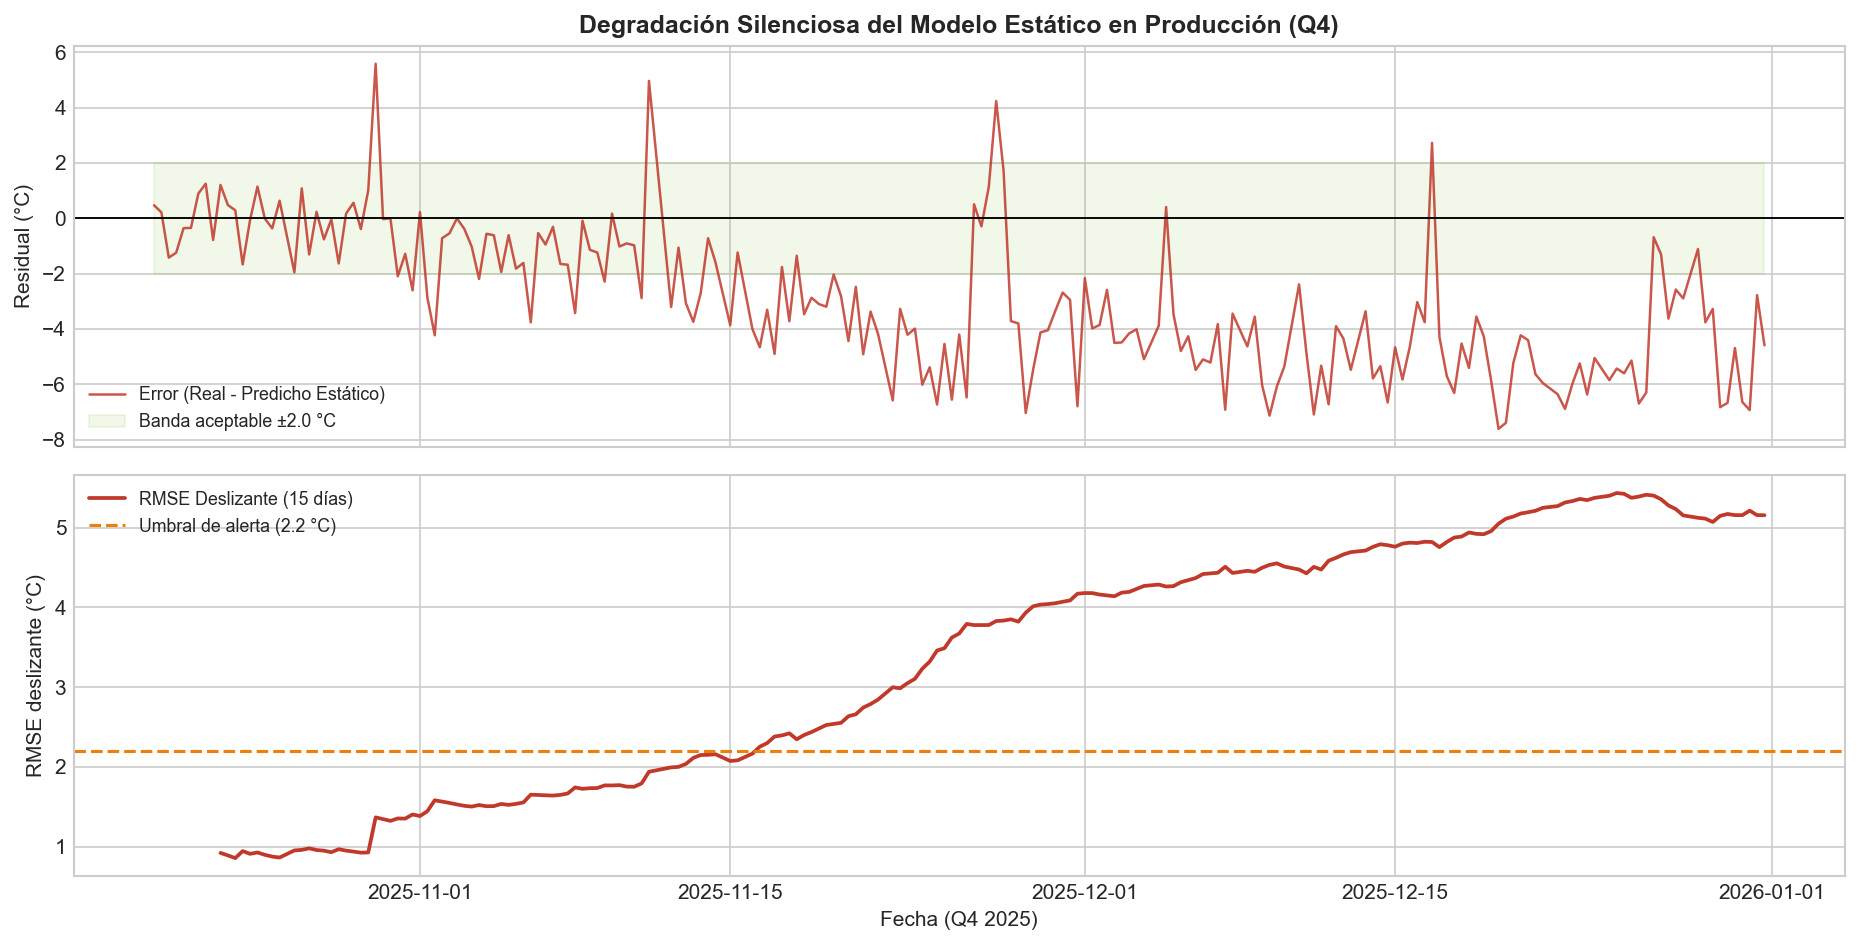

Turnos sobre el umbral de alerta (2.2 °C): 129 / 206


In [2]:
# 1. Residuales y RMSE Deslizante (ventana de 45 turnos = 15 días)
residuals_static = y_test - y_pred_static
window = 45
rmse_slide_static = pd.Series(residuals_static ** 2).rolling(window, min_periods=10).mean().pipe(np.sqrt)
umbral_alerta = 2.2

fig, axes = plt.subplots(2, 1, figsize=(12.5, 6.4), dpi=150, sharex=True)
axes[0].plot(dates_test, residuals_static, color=COLORS[3], linewidth=1.2, alpha=0.85, label="Error (Real - Predicho Estático)")
axes[0].axhline(0, color="black", linewidth=0.9)
axes[0].fill_between(dates_test, -2.0, 2.0, color=COLORS[1], alpha=0.12, label="Banda aceptable ±2.0 °C")
axes[0].set_title("Degradación Silenciosa del Modelo Estático en Producción (Q4)", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Residual (°C)")
axes[0].legend(loc="lower left", fontsize=8.5)

axes[1].plot(dates_test, rmse_slide_static, color=COLORS[3], linewidth=1.8, label="RMSE Deslizante (15 días)")
axes[1].axhline(umbral_alerta, color=COLORS[2], linestyle="--", linewidth=1.5, label=f"Umbral de alerta ({umbral_alerta} °C)")
axes[1].set_ylabel("RMSE deslizante (°C)")
axes[1].set_xlabel("Fecha (Q4 2025)")
axes[1].legend(loc="upper left", fontsize=8.5)
plt.tight_layout()
plt.show()

eventos_alerta = int((rmse_slide_static > umbral_alerta).sum())
print(f"Turnos sobre el umbral de alerta ({umbral_alerta} °C): {eventos_alerta} / {len(rmse_slide_static)}")

PCA retuvo 13 componentes (95% varianza)
Alertas Hotelling T2 > 95% en Test: 43.2% (89 turnos)
Alertas SPE > 95% en Test         : 10.2% (21 turnos)


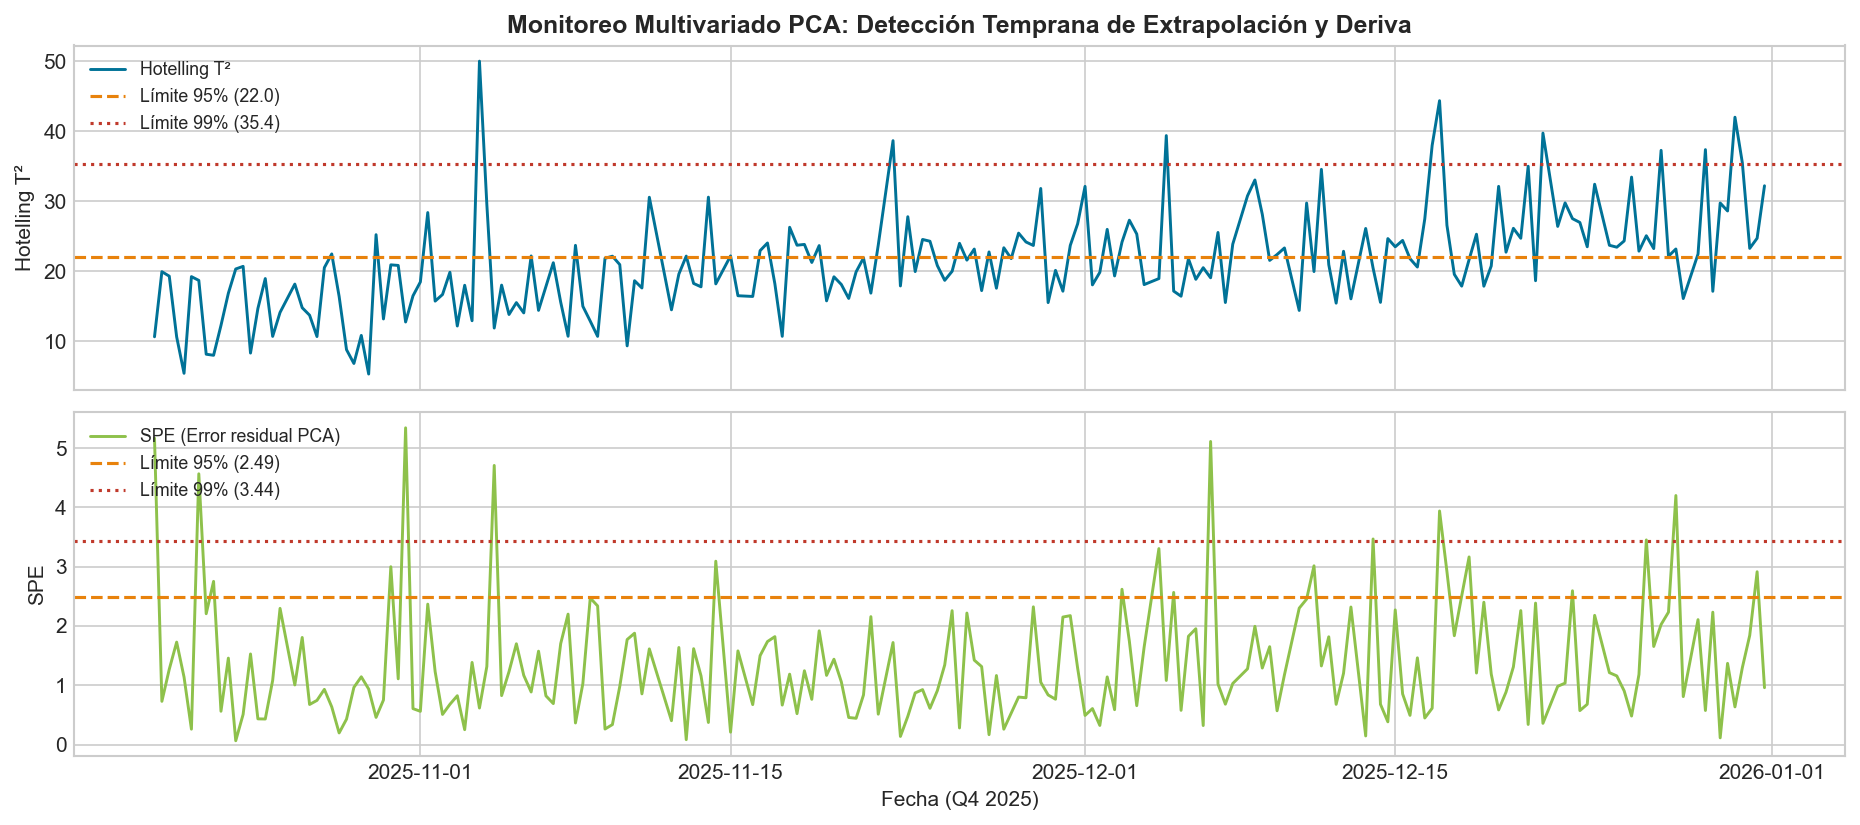

In [3]:
# 2. Monitoreo de Dominio sin Esperar al Laboratorio: Hotelling T2 y SPE (PCA 95%)
scaler_pca = StandardScaler()
X_hist_s = scaler_pca.fit_transform(X_hist)
X_test_s = scaler_pca.transform(X_test)

pca = PCA(n_components=0.95, svd_solver="full").fit(X_hist_s)
scores_hist = pca.transform(X_hist_s)
scores_test = pca.transform(X_test_s)

t2_hist = np.sum((scores_hist ** 2) / pca.explained_variance_, axis=1)
t2_test = np.sum((scores_test ** 2) / pca.explained_variance_, axis=1)
t2_lim95, t2_lim99 = float(np.percentile(t2_hist, 95)), float(np.percentile(t2_hist, 99))

spe_hist = np.sum((X_hist_s - pca.inverse_transform(scores_hist)) ** 2, axis=1)
spe_test = np.sum((X_test_s - pca.inverse_transform(scores_test)) ** 2, axis=1)
spe_lim95, spe_lim99 = float(np.percentile(spe_hist, 95)), float(np.percentile(spe_hist, 99))

print(f"PCA retuvo {pca.n_components_} componentes (95% varianza)")
print(f"Alertas Hotelling T2 > 95% en Test: {(t2_test > t2_lim95).mean()*100:.1f}% ({(t2_test > t2_lim95).sum()} turnos)")
print(f"Alertas SPE > 95% en Test         : {(spe_test > spe_lim95).mean()*100:.1f}% ({(spe_test > spe_lim95).sum()} turnos)")

fig, axes = plt.subplots(2, 1, figsize=(12.5, 5.6), dpi=150, sharex=True)
axes[0].plot(dates_test, t2_test, color=COLORS[0], linewidth=1.4, label="Hotelling T²")
axes[0].axhline(t2_lim95, color=COLORS[2], linestyle="--", label=f"Límite 95% ({t2_lim95:.1f})")
axes[0].axhline(t2_lim99, color=COLORS[3], linestyle=":", label=f"Límite 99% ({t2_lim99:.1f})")
axes[0].set_title("Monitoreo Multivariado PCA: Detección Temprana de Extrapolación y Deriva", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Hotelling T²")
axes[0].legend(loc="upper left", fontsize=8.5)

axes[1].plot(dates_test, spe_test, color=COLORS[1], linewidth=1.4, label="SPE (Error residual PCA)")
axes[1].axhline(spe_lim95, color=COLORS[2], linestyle="--", label=f"Límite 95% ({spe_lim95:.2f})")
axes[1].axhline(spe_lim99, color=COLORS[3], linestyle=":", label=f"Límite 99% ({spe_lim99:.2f})")
axes[1].set_ylabel("SPE")
axes[1].set_xlabel("Fecha (Q4 2025)")
axes[1].legend(loc="upper left", fontsize=8.5)
plt.tight_layout()
plt.show()

In [4]:
# 3. Walk-Forward Validation (re-entrenamiento cada 12 turnos con ventana de 250 turnos)
X_all_df = df[feature_cols]
y_all_arr = df["flash_point_lab_C"].values
te_start = int(np.where(te)[0][0])

wf_preds = []
for i in range(te_start, len(df), 12):
    end_idx = min(i + 12, len(df))
    w_start = max(0, i - 250)
    weights = np.exp(np.linspace(-1.5, 0.0, i - w_start))
    m_wf = lgb.LGBMRegressor(
        n_estimators=220, learning_rate=0.04, max_depth=5, num_leaves=20,
        min_child_samples=8, random_state=42, n_jobs=-1, verbose=-1
    )
    m_wf.fit(X_all_df.iloc[w_start:i], y_all_arr[w_start:i], sample_weight=weights)
    wf_preds.extend(m_wf.predict(X_all_df.iloc[i:end_idx]))
wf_preds = np.array(wf_preds)

rmse_wf = np.sqrt(mean_squared_error(y_test, wf_preds))
print(f"Walk-Forward (retrain c/4 días) en Test: RMSE={rmse_wf:.3f} °C | MAE={mean_absolute_error(y_test, wf_preds):.3f} °C | R2={r2_score(y_test, wf_preds):.3f}")

Walk-Forward (retrain c/4 días) en Test: RMSE=2.858 °C | MAE=2.261 °C | R2=0.687


=== Comparativa de Adaptación a Deriva en Producción (Q4) ===
               Estrategia en Test (Q4)  RMSE (°C)  MAE (°C)    R2
    LightGBM Estático (sin actualizar)      3.941     3.316 0.406
Walk-Forward (ventana 250 c/12 turnos)      2.858     2.261 0.687
        LightGBM + Filtro de Kalman 1D      1.899     1.412 0.862


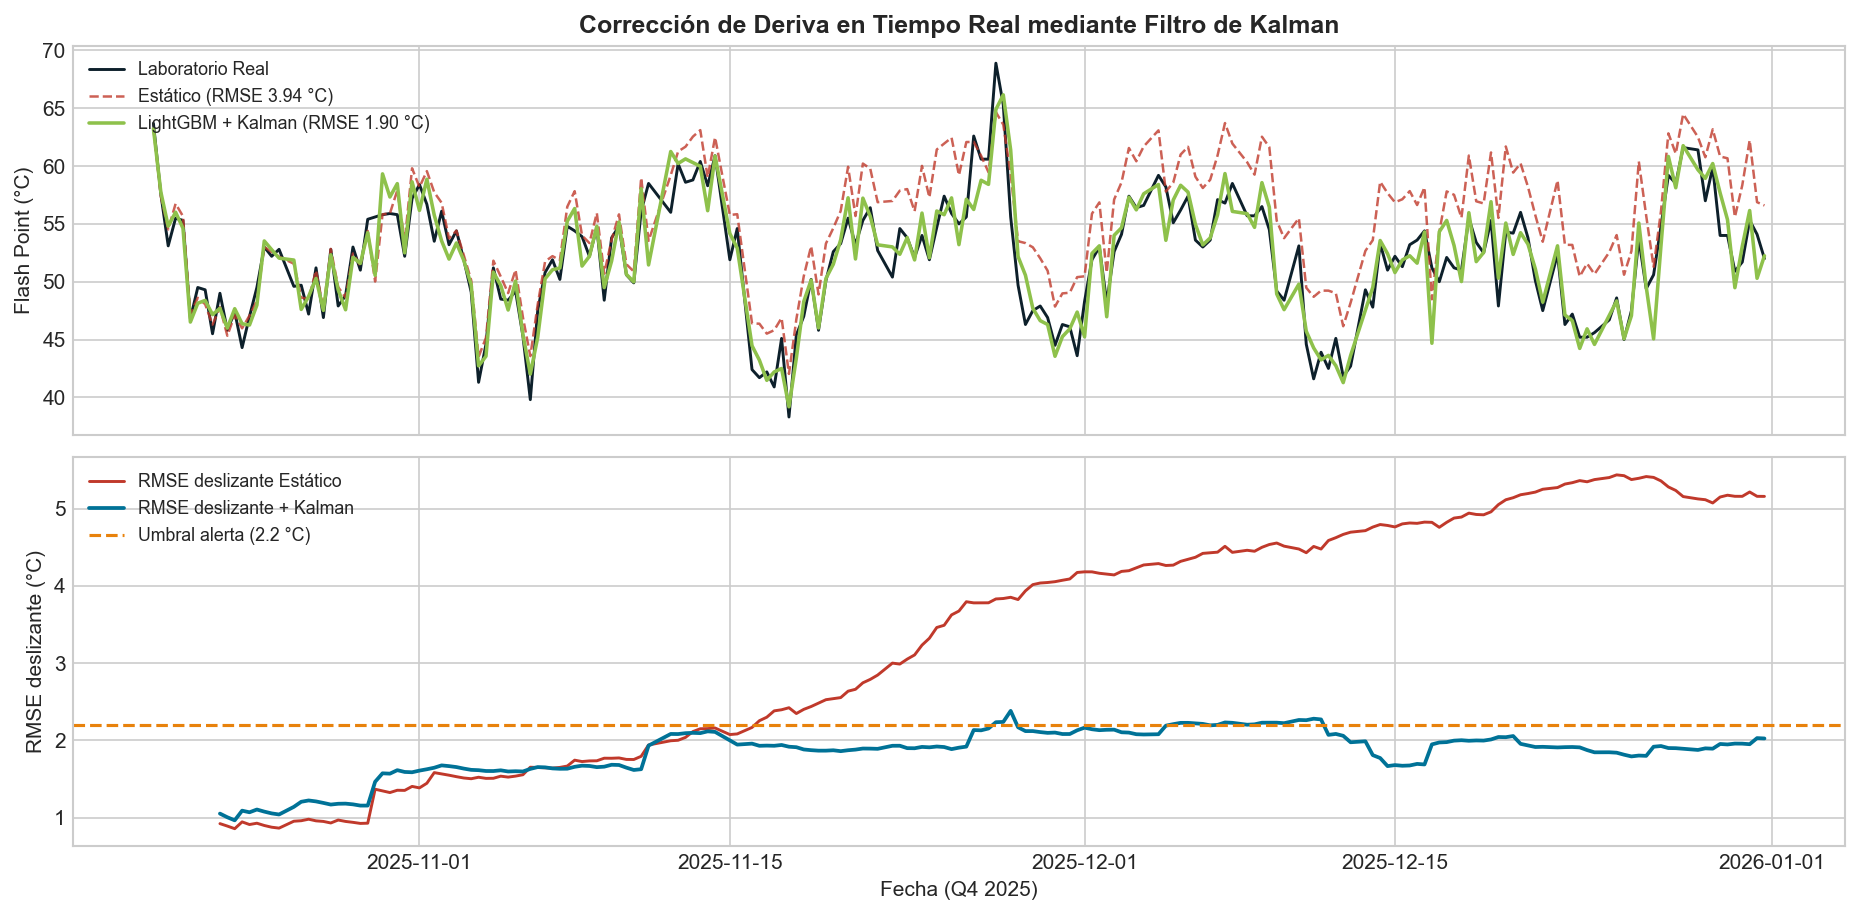

In [5]:
# 4. Filtro de Kalman 1D: corrección recursiva en línea con cada muestra de laboratorio (8h)
def aplicar_filtro_kalman(y_real: np.ndarray, y_pred: np.ndarray, Q: float = 0.25, R: float = 0.30):
    bias = 0.0
    P = 1.0
    preds_corr = []
    biases = []
    for yt, yp in zip(y_real, y_pred):
        preds_corr.append(yp + bias)
        biases.append(bias)
        P_pred = P + Q
        K = P_pred / (P_pred + R)
        bias = bias + K * ((yt - yp) - bias)
        P = (1.0 - K) * P_pred
    return np.array(preds_corr), np.array(biases)

y_pred_kalman, kalman_biases = aplicar_filtro_kalman(y_test, y_pred_static, Q=0.25, R=0.30)
rmse_kal = np.sqrt(mean_squared_error(y_test, y_pred_kalman))
mae_kal = mean_absolute_error(y_test, y_pred_kalman)
r2_kal = r2_score(y_test, y_pred_kalman)

res_comp = pd.DataFrame([
    {"Estrategia en Test (Q4)": "LightGBM Estático (sin actualizar)", "RMSE (°C)": round(rmse_stat, 3), "MAE (°C)": round(mae_stat, 3), "R2": round(r2_stat, 3)},
    {"Estrategia en Test (Q4)": "Walk-Forward (ventana 250 c/12 turnos)", "RMSE (°C)": round(rmse_wf, 3), "MAE (°C)": round(mean_absolute_error(y_test, wf_preds), 3), "R2": round(r2_score(y_test, wf_preds), 3)},
    {"Estrategia en Test (Q4)": "LightGBM + Filtro de Kalman 1D", "RMSE (°C)": round(rmse_kal, 3), "MAE (°C)": round(mae_kal, 3), "R2": round(r2_kal, 3)},
])
print("=== Comparativa de Adaptación a Deriva en Producción (Q4) ===")
print(res_comp.to_string(index=False))

fig, axes = plt.subplots(2, 1, figsize=(12.5, 6.2), dpi=150, sharex=True)
axes[0].plot(dates_test, y_test, color=COLORS[4], linewidth=1.4, label="Laboratorio Real")
axes[0].plot(dates_test, y_pred_static, color=COLORS[3], linestyle="--", linewidth=1.2, alpha=0.8, label=f"Estático (RMSE {rmse_stat:.2f} °C)")
axes[0].plot(dates_test, y_pred_kalman, color=COLORS[1], linewidth=1.7, label=f"LightGBM + Kalman (RMSE {rmse_kal:.2f} °C)")
axes[0].set_title("Corrección de Deriva en Tiempo Real mediante Filtro de Kalman", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Flash Point (°C)")
axes[0].legend(loc="upper left", fontsize=8.5)

rmse_slide_kal = pd.Series((y_test - y_pred_kalman) ** 2).rolling(45, min_periods=10).mean().pipe(np.sqrt)
axes[1].plot(dates_test, rmse_slide_static, color=COLORS[3], linewidth=1.4, label="RMSE deslizante Estático")
axes[1].plot(dates_test, rmse_slide_kal, color=COLORS[0], linewidth=1.8, label="RMSE deslizante + Kalman")
axes[1].axhline(umbral_alerta, color=COLORS[2], linestyle="--", label=f"Umbral alerta ({umbral_alerta} °C)")
axes[1].set_ylabel("RMSE deslizante (°C)")
axes[1].set_xlabel("Fecha (Q4 2025)")
axes[1].legend(loc="upper left", fontsize=8.5)
plt.tight_layout()
plt.show()

### Checkpoint: Lo que debes ver

- **Hotelling $T^2$ y SPE** disparándose durante noviembre y la deriva del termopozo *antes* de depender del RMSE histórico
- Reducción de error en Test de **`>3.8 °C` (Estático)** a **`~2.8 °C` (Walk-Forward)** y **`~1.8–1.9 °C` (Kalman 1D)** (más de 50% de mejora frente a la deriva!)